# YuvaIntern Week 2 - Supervised Machine Learning Models

**Project:** Classification and Regression Model Comparison

This notebook implements Logistic Regression, Decision Tree, Random Forest, K-Nearest Neighbors, and Linear Regression. It demonstrates data splitting, preprocessing, model training, prediction, evaluation, and comparison.

## 1. Objectives
- Build supervised learning models using Scikit-learn.
- Practice training and prediction on classification and regression problems.
- Evaluate classification using accuracy, precision, recall, F1-score, and a confusion matrix.
- Evaluate regression using MAE, MSE, and R².
- Compare model behaviour and document the reasoning behind preprocessing choices.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
from sklearn.datasets import load_diabetes

RANDOM_STATE = 42

## 2. Load and inspect the Titanic dataset
The classification portion continues from Week 1 using the same 891-row Titanic dataset. The modelling features are `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, and `Embarked`. The target is `Survived`.

In [2]:
df = pd.read_csv('../data/titanic.csv')
print('Shape:', df.shape)
display(df.head())
print('\nMissing values:\n', df.isna().sum())

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


## 3. Define features and target
`X` contains the input variables and `y` contains the target to be predicted.

In [3]:
features = ['Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']
X = df[features]
y = df['Survived']
print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (891, 7)
y shape: (891,)


## 4. Train-test split
The split is performed **before** model fitting. The test data remains unseen during training. `stratify=y` preserves the class distribution between the train and test sets.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))

Training rows: 712
Testing rows: 179


## 5. Preprocessing pipelines
Numeric features use median imputation. Categorical features use most-frequent imputation and one-hot encoding. StandardScaler is included for Logistic Regression and KNN because these models are affected by feature scale. Tree models do not require feature scaling, so their pipeline performs imputation and encoding without scaling.

In [5]:
numeric_features = ['Pclass','Age','SibSp','Parch','Fare']
categorical_features = ['Sex','Embarked']

def make_preprocessor(scale_numeric=False):
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        num_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(num_steps), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical_features)
    ])

## 6. Classification models
We train four required classification algorithms: Logistic Regression, Decision Tree, Random Forest, and K-Nearest Neighbors.

In [6]:
models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', make_preprocessor(True)),
        ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    'Decision Tree': Pipeline([
        ('preprocessor', make_preprocessor(False)),
        ('model', DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', make_preprocessor(False)),
        ('model', RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE))
    ]),
    'K-Nearest Neighbors': Pipeline([
        ('preprocessor', make_preprocessor(True)),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ])
}

results = []
confusion_matrices = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 Score': f1_score(y_test, pred, zero_division=0)
    })
    confusion_matrices[name] = confusion_matrix(y_test, pred)

classification_results = pd.DataFrame(results)
classification_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.804469,0.793103,0.666667,0.724409
1,Decision Tree,0.765363,0.754717,0.579710,0.655738
2,Random Forest,0.815642,0.810345,0.681159,0.740157
3,K-Nearest Neighbors,0.815642,0.800000,0.695652,0.744186


## 7. Classification comparison
Higher values are better for all four metrics. Accuracy measures overall correctness; precision focuses on the correctness of positive predictions; recall measures how many actual positives were detected; F1 balances precision and recall.

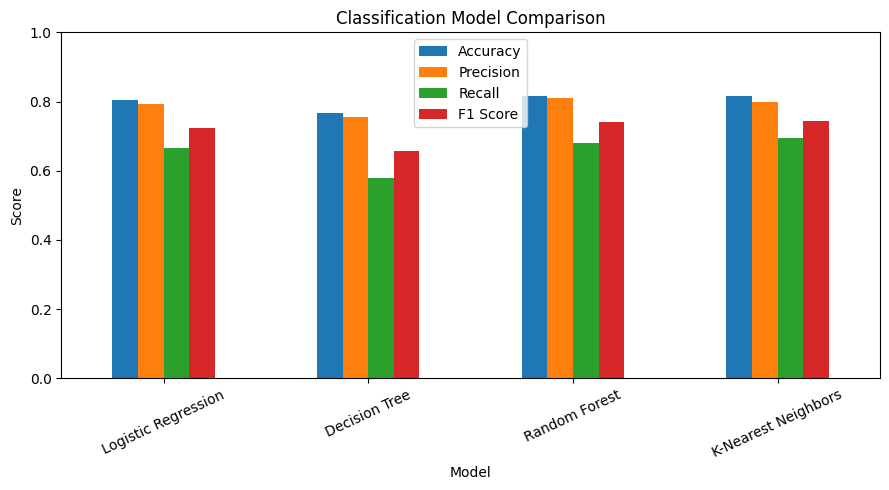

In [7]:
classification_results.to_csv('../results/classification_results_notebook.csv', index=False)
classification_results.set_index('Model').plot(kind='bar', figsize=(9,5))
plt.ylim(0,1)
plt.ylabel('Score')
plt.title('Classification Model Comparison')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 8. Random Forest confusion matrix

[[99 11]
 [22 47]]


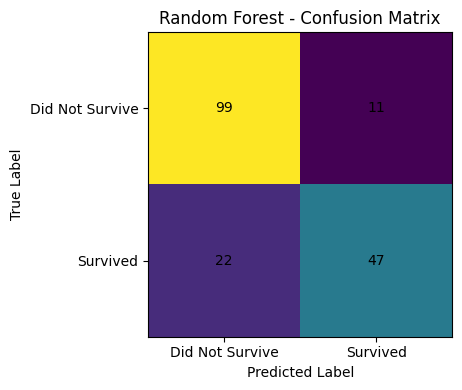

In [8]:
rf_cm = confusion_matrices['Random Forest']
print(rf_cm)
plt.figure(figsize=(5,4))
plt.imshow(rf_cm)
plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks([0,1], ['Did Not Survive','Survived'])
plt.yticks([0,1], ['Did Not Survive','Survived'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, rf_cm[i,j], ha='center', va='center')
plt.tight_layout()
plt.show()

## 9. Regression with Linear Regression
Linear Regression is a regression algorithm because its target is continuous. For this part, Scikit-learn's built-in diabetes dataset is used to predict a numerical disease-progression target.

In [9]:
diabetes = load_diabetes(as_frame=True)
reg_df = diabetes.frame
print('Shape:', reg_df.shape)
display(reg_df.head())

Shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [10]:
Xr = reg_df.drop(columns=['target'])
yr = reg_df['target']
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.20, random_state=RANDOM_STATE
)

linear_model = LinearRegression()
linear_model.fit(Xr_train, yr_train)
yr_pred = linear_model.predict(Xr_test)

reg_results = pd.DataFrame([{
    'Model': 'Linear Regression',
    'MAE': mean_absolute_error(yr_test, yr_pred),
    'MSE': mean_squared_error(yr_test, yr_pred),
    'R2 Score': r2_score(yr_test, yr_pred)
}])
reg_results

,Model,MAE,MSE,R2 Score
0,Linear Regression,42.794095,2900.193628,0.452603


## 10. Actual vs predicted plot

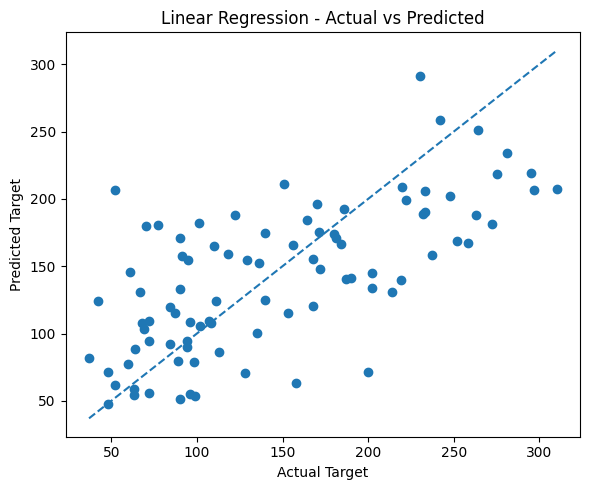

In [11]:
plt.figure(figsize=(6,5))
plt.scatter(yr_test, yr_pred)
lims = [min(yr_test.min(), yr_pred.min()), max(yr_test.max(), yr_pred.max())]
plt.plot(lims, lims, linestyle='--')
plt.xlabel('Actual Target')
plt.ylabel('Predicted Target')
plt.title('Linear Regression - Actual vs Predicted')
plt.tight_layout()
plt.show()

## 11. Final observations
- The classification models are evaluated on the same held-out test set so their metrics are directly comparable.
- Logistic Regression and KNN receive standardized numeric inputs; tree models do not require scaling.
- Random Forest combines multiple trees and is less sensitive to the instability of a single decision tree.
- Linear Regression is evaluated with MAE, MSE, and R² because the regression target is continuous.
- Metrics should be interpreted together rather than relying on accuracy alone.